# Randomized sensing pulse design
Enter known frequencies and hardware timings, generate a random pulse pool,
and export a phase-locked or freely running acquisition. After collecting counts, choose
which observables to evaluate. You can change those weights and reuse the same
saved counts for decoding and validation.

RQS uses approximate moment inversion; RQS-ML refines it using the actual pulse
responses. Neither result has a certified confidence interval.
All frequencies are in Hz and times in seconds.

In [1]:
from pathlib import Path
import sys
import importlib
import numpy as np
import matplotlib.pyplot as plt

candidates = [p for parent in (Path.cwd(), *Path.cwd().parents)
              for p in (parent, parent / "Algorithmic_Sensing_Toolkit")]
ROOT = next(p for p in candidates if (p / "src/randomized_sensing").is_dir())
sys.path.insert(0, str(ROOT / "src"))
# Refresh this package when rerunning after local code edits.
for name in tuple(sys.modules):
    if name.split(".")[0] in ("randomized_sensing", "matched_sensing"):
        del sys.modules[name]
importlib.invalidate_caches()
import randomized_sensing as R
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Specify frequencies and hardware

The field is $b(t)=\sum_j[a_j\cos(2\pi f_jt)+b_j\sin(2\pi f_jt)]$ and
$H=(2\pi\,\mathrm{coupling\_hz})b(t)Z/2$. The amplitude vector $A$ contains
all cosine amplitudes followed by all sine amplitudes.

List **all** possible input frequencies. They need not be equally spaced;
DC is currently unsupported. Observable weights are chosen in step 6,
after the acquisition. No observables enter these experiment settings.

In [2]:
experiment = R.Experiment(
    frequencies_hz=(.8e6, 1.05e6, 1.31e6, 1.72e6),
    coupling_hz=100e3,
    t2_s=200e-6,             # None removes dephasing
    amplitude_bound=1.,     # bound on ||all cosine and sine amplitudes||_2
    min_gap_s=20e-9,
    edge_guard_s=20e-9,
    clock_s=2.5e-9,          # actual hardware timing grid; None permits a numerical design grid
    visibility=1.,
    readout_bias=0.,         # calibrated additive offset in the RAW +/-1 mean
    overhead_s=0.,          # preparation/reset/readout time per shot
)

FIELD_MODE = "phase_locked"  # choose "free_running" to use actual per-shot timestamps, choose phase_locked if you have reset and want to start from the same reference
SHOT_PERIOD_S = 20.0375e-6   # freely running schedule: sensing + preparation/readout/reset

## 2. Build and inspect random pulses

Random multisine phases are uniform on $[0,2\pi)$. Short runs are merged,
then responses are integrated over the actual intervals. The pool contains
independent patterns and their negatives. `pool_size` defaults to
`max(8192, 64*N)`; half that many patterns are independently generated.

The hardware clock takes precedence over `design_clock_s`. Every interval
conservatively obeys `max(min_gap_s, edge_guard_s)`, rounded **up** to the grid.
The duration must contain a whole number of grid cells. `max_pulses` rejects
longer pulse trains. These settings can affect the response distribution.

`start_time_s` defines the reference time for the stored pulse responses.
In `phase_locked` mode, each shot reproduces those starting tone phases.
In `free_running` mode, the same waveforms run at different phases and the
decoder rotates each response using its measured sensing-start timestamp.
Use a common stable clock origin; an unknown initial source phase is absorbed
into the Fourier amplitudes. Source reset is unnecessary in freely running mode.

In [3]:
pool = R.build_pool(
    experiment,
    duration_s=20e-6,
    max_pulses=64, #use None if you do not have an additional tighter limit on the pulse count
    pool_size=None,
    start_time_s=123e-9,
    design_clock_s=2.5e-9,   # numerical grid only when experiment.clock_s is None
    seed=4,
)
checks = [R.audit(pool, i) for i in range(len(pool.sequences))]
assert all(c["timing_valid"] for c in checks)
print(f"Pool: {len(pool.Z)} signed responses; {len(pool.sequences)} independent patterns")
print(f"Actual design grid: {pool.design_clock_s*1e9:g} ns")
print(f"Smallest interval: {min(c['minimum_interval_s'] for c in checks)*1e9:.3f} ns")
print(f"Largest pulse count: {max(c['pulse_count'] for c in checks)}")
print(f"Covariance condition number: {np.linalg.cond(pool.Sigma):.3f}")

Pool: 8192 signed responses; 4096 independent patterns
Actual design grid: 2.5 ns
Smallest interval: 20.000 ns
Largest pulse count: 60
Covariance condition number: 1.335


Y outcome sign: -1


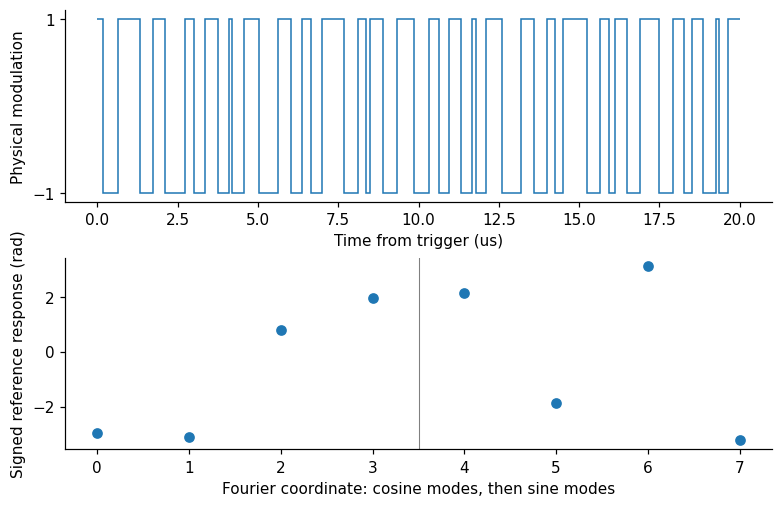

In [4]:
index = 1
sequence = pool.sequence(index)
edges = np.r_[0., sequence.switch_times_s, pool.duration_s]
fig, axes = plt.subplots(2, 1, figsize=(7, 4.5), constrained_layout=True)
axes[0].stairs((-1.)**np.arange(len(edges)-1), edges*1e6, baseline=None)
axes[0].set(xlabel="Time from trigger (us)", ylabel="Physical modulation", yticks=[-1, 1])
axes[1].plot(np.arange(2*pool.N), pool.Z[index], "o")
axes[1].axvline(pool.N-.5, color="grey", lw=.7)
axes[1].set(xlabel="Fourier coordinate: cosine modes, then sine modes", ylabel="Signed reference response (rad)")
print("Y outcome sign:", R.audit(pool, index)["y_outcome_sign"])
plt.show()

## 3. Freeze a shot budget

Entries are drawn uniformly with replacement for X and Y shots. `n_shots` includes
both bases and is a chosen budget, not a promised precision. T2 enters the shot
contrast; duration is an explicit choice and is not optimized here.

- `phase_locked`: repeated sequence/basis pairs are grouped into count rows.
- `free_running`: one row per shot, random X/Y interleaving, and a nominal start
  schedule using `SHOT_PERIOD_S`. The period includes sensing plus reset/readout
  time. You can instead supply a full `start_times_s` schedule to `plan_acquisition`.

Measured timestamps are recorded later; they can differ from the planned schedule.

In [5]:
timing_options = (dict(shot_period_s=SHOT_PERIOD_S)
                  if FIELD_MODE == "free_running" else {})
plan = R.plan_acquisition(pool, n_shots=20_000, x_fraction=.2, seed=5,
                          field_mode=FIELD_MODE, **timing_options)
print("Field mode:", plan.field_mode)
print(f"Shots: {plan.total_shots:,}; acquisition rows: {len(plan.rows):,}")
print(f"Expected contrast: {experiment.contrast(pool.duration_s):.4f}")
print(f"Active sensing: {plan.active_time_s*1e3:.2f} ms")
print(f"Including specified per-shot overhead: {plan.time_with_overhead_s*1e3:.2f} ms")
if plan.scheduled_span_s is not None:
    print(f"Scheduled first-start to last-end span: {plan.scheduled_span_s*1e3:.2f} ms")
    print("This span excludes final readout overhead; record actual starts during acquisition.")
else:
    print("Additional phase-reference waits are not included.")

Field mode: phase_locked
Shots: 20,000; acquisition rows: 10,240
Expected contrast: 0.9048
Active sensing: 400.00 ms
Including specified per-shot overhead: 400.00 ms
Additional phase-reference waits are not included.


## 4. Export for hardware

`pulses.csv` lists only internal X(pi) pulses. Physical modulation always starts
at +1, including negative pool entries; no extra initial or final pulse is needed.
The decoder handles virtual response signs and odd-pulse Y-frame parity using
`outcome_sign` in `acquisition.csv`.

Read `RUN.txt`, implement its physical X/Y measurement convention, and fill a
**copy** of `counts_template.csv` with raw physical +1 counts. Do not apply sign
corrections or subtract the readout bias yourself. Re-executing the next cell
replaces generated bundle files; save measured counts separately.

For `free_running`, each row is a single shot. Record both its raw `plus`
outcome (0 or 1) and its **actual** `start_time_s` in the counts CSV. The
exported `planned_start_time_s` is only a nominal schedule. Use elapsed seconds
from one stable clock origin, not Unix timestamps; timestamp precision must
resolve the fastest tone. Do not group shots taken at different times.

In [6]:
folder = "randomized_free_running_example" if FIELD_MODE == "free_running" else "randomized_example"
output = R.export_bundle(plan, ROOT / "outputs" / folder, overwrite=True)
for name in ("sequences.csv", "pulses.csv", "intervals.csv", "acquisition.csv",
             "counts_template.csv", "bundle.json", "pool.npz", "manifest.json", "RUN.txt"):
    print((output / name).relative_to(ROOT))

outputs/randomized_example/sequences.csv
outputs/randomized_example/pulses.csv
outputs/randomized_example/intervals.csv
outputs/randomized_example/acquisition.csv
outputs/randomized_example/counts_template.csv
outputs/randomized_example/bundle.json
outputs/randomized_example/pool.npz
outputs/randomized_example/manifest.json
outputs/randomized_example/RUN.txt


## 5. Optional simulated measurement

This example uses a dense field of norm 0.5. The simulation uses the actual
repaired responses and calibrated dephasing/readout model. The decoder receives
only the saved plan and counts. Skip this cell when using hardware data.

For freely running mode, the demo adds small synthetic trigger delays and saves
the actual timestamps with the outcomes. Hardware must supply its measured
sensing-start timestamps from the acquisition clock.

In [7]:
rng = np.random.default_rng(4)
amplitudes = rng.normal(size=2*pool.N)
amplitudes *= .5*experiment.amplitude_bound/np.linalg.norm(amplitudes)
actual_starts = None
if plan.field_mode == "free_running":
    scheduled_starts = np.array([row["start_time_s"] for row in plan.rows])
    actual_starts = scheduled_starts + rng.uniform(0., 10e-9, len(plan.rows))
demo_counts = R.simulate(plan, amplitudes, seed=42, start_times_s=actual_starts)
R.write_counts(output / "demo_counts.csv", plan, demo_counts)
print("Saved simulated RAW counts to", output / "demo_counts.csv")

Saved simulated RAW counts to /Users/aditi/Documents/Numerics/Algorithmic Spectroscopy/Algorithmic_Sensing_Toolkit/outputs/randomized_example/demo_counts.csv


## 6. Choose observables after acquisition

Each row below defines $F_j=\sum_k c_{jk}a_k+s_{jk}b_k$. Columns follow the
frequency order in step 1. Use matching `(N,)` vectors for one observable or
`(M,N)` arrays for several. Add, remove, or change rows as needed.

**To try different observables, edit this cell and rerun steps 6 onward.**
The pulse pool, exported acquisition, and measured counts are reused.

In [8]:
# Edit these weights freely after collecting the data.
cosine_weights = np.array([[.5, -.3, 0., .4], [.1, .2, -.4, .3]])
sine_weights = np.array([[.2, .4, .1, -.2], [-.3, .1, .2, .25]])
observable_weights = dict(cosine_weights=cosine_weights, sine_weights=sine_weights)

## 7. Decode the selected observables

Select your completed hardware CSV below. Phase-locked data support RQS moment
inversion and its RQS-ML likelihood refinement. `floor_active=True` exposes the
small-X-mean guard in those estimators.

Freely running data use `TIMESTAMPED-ML`: it computes actual per-shot responses
from recorded timestamps and jointly fits amplitudes and contrast within the
amplitude norm bound. It requires at least `3*2N` total shots and a full-rank
Y-response design. Missing timestamps or failed fits raise an error.

The weights are applied after amplitude reconstruction; changing them reuses
the same acquisition and counts. These are local fits, without certified
confidence intervals or a global-optimum guarantee.

In [9]:
counts_file = output / "demo_counts.csv"  # replace with your completed hardware CSV
saved_plan = R.load_bundle(output)
counts = R.read_counts(counts_file, saved_plan)
methods = ("TIMESTAMPED-ML",) if saved_plan.field_mode == "free_running" else ("RQS", "RQS-ML")
results = {method: R.decode(saved_plan, counts, method=method, **observable_weights)
           for method in methods}
for method, result in results.items():
    print(method)
    for j, value in enumerate(result.values, start=1):
        print(f"  F{j}: {value:.6f}")
    if result.guard_floor is not None:
        print(f"  X mean={result.x_mean:.4f}, guard={result.guard_floor:.4f}, floor active={result.floor_active}")
    if result.fit_converged is not None:
        print(f"  Fit converged={result.fit_converged}; Y-response condition={result.response_condition:.3f}")
    print(f"  Likelihood applied={result.ml_applied}, fitted contrast={result.fitted_contrast}")
if isinstance(counts, R.TimedCounts):
    actual_times = np.array([counts.start_times_s[row["row_id"]] for row in saved_plan.rows])
    span = actual_times[-1]-actual_times[0]+saved_plan.pool.duration_s
    print(f"Measured first-start to last-end span: {span*1e3:.2f} ms (excludes final readout)")

RQS
  F1: -0.082391
  F2: -0.029198
  X mean=0.3275, guard=0.0190, floor active=False
  Likelihood applied=False, fitted contrast=None
RQS-ML
  F1: -0.080370
  F2: -0.029361
  X mean=0.3275, guard=0.0190, floor active=False
  Likelihood applied=True, fitted contrast=0.9096640195489748


## 8. Optional validation on a known synthetic field

Run these cells only after the simulation cell. In phase-locked mode, population
moments expose RQS approximation error without shot noise. In freely running
mode, exact outcome probabilities at the measured timestamps pass through the
same likelihood fit, checking numerical inversion without shot noise.

The second check repeats independent noisy measurements. Both checks use the
current weights from step 6 and the same actual timestamp table when present.
They do not prove performance for every input field or schedule. For hardware
counts without known truth, skip this section.

RQS-population noise-free error per query: [-0.00650123  0.00356085]


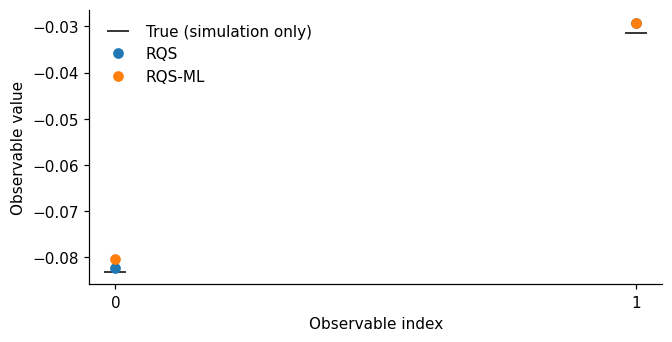

In [10]:
# Remove outcome noise while retaining this field and the actual timing table.
validation_timing = (dict(start_times_s=counts.start_times_s)
                     if isinstance(counts, R.TimedCounts) else {})
population = R.population_estimate(saved_plan, amplitudes, **observable_weights, **validation_timing)
truth = np.asarray(R.evaluate_observables(amplitudes, **observable_weights))
print(population.method, "noise-free error per query:", np.asarray(population.values)-truth)

fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
x = np.arange(len(truth))
ax.plot(x, truth, "k_", ms=15, label="True (simulation only)")
for method, result in results.items():
    ax.plot(x, result.values, "o", label=method)
ax.set(xlabel="Observable index", ylabel="Observable value", xticks=x)
ax.legend(frameon=False)
plt.show()

In [11]:
RUN_REPEATED_TRIALS = False  # optional; evaluates this field and fixed acquisition only
if RUN_REPEATED_TRIALS:
    errors = {method: [] for method in results}
    for seed in range(100, 130):
        trial_counts = R.simulate(saved_plan, amplitudes, seed=seed, **validation_timing)
        for method in errors:
            estimate = R.decode(saved_plan, trial_counts, method=method, **observable_weights)
            errors[method].append(np.max(abs(np.asarray(estimate.values)-truth)))
    for method, values in errors.items():
        print(method, "median / 95th percentile max query error:", np.quantile(values, [.5, .95]))

Frequencies and global Fourier amplitudes must remain fixed during acquisition.
Phase-locked mode requires reproducible starting phases; freely running mode
requires accurate timestamps from one stable clock. Finite pulse widths, timing
uncertainty, field drift, and calibration uncertainty are not modeled.
See [randomized protocol and conventions](../docs/randomized.md).